# IMPORT LIBRARY

In [257]:
import os 
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectKBest
from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, regularizers
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve, average_precision_score
import joblib
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import layers
from tensorflow.keras.models import load_model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef,
    balanced_accuracy_score
)

In [258]:
folder = r"D:\2025 FILES\PROJECT WORK\ABT_NGL_5943\alzheimers_disease_data.csv"
data = pd.read_csv(folder)

In [259]:
data

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,6895,61,0,0,1,39.121757,0,1.561126,4.049964,6.555306,...,0,0,4.492838,1,0,0,0,0,1,XXXConfid
2145,6896,75,0,0,2,17.857903,0,18.767261,1.360667,2.904662,...,0,1,9.204952,0,0,0,0,0,1,XXXConfid
2146,6897,77,0,0,1,15.476479,0,4.594670,9.886002,8.120025,...,0,0,5.036334,0,0,0,0,0,1,XXXConfid
2147,6898,78,1,3,1,15.299911,0,8.674505,6.354282,1.263427,...,0,0,3.785399,0,0,0,0,1,1,XXXConfid


In [260]:
data.shape

(2149, 35)

In [261]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes                   2149 non-null   int64

In [262]:
data.isnull().sum()

PatientID                    0
Age                          0
Gender                       0
Ethnicity                    0
EducationLevel               0
BMI                          0
Smoking                      0
AlcoholConsumption           0
PhysicalActivity             0
DietQuality                  0
SleepQuality                 0
FamilyHistoryAlzheimers      0
CardiovascularDisease        0
Diabetes                     0
Depression                   0
HeadInjury                   0
Hypertension                 0
SystolicBP                   0
DiastolicBP                  0
CholesterolTotal             0
CholesterolLDL               0
CholesterolHDL               0
CholesterolTriglycerides     0
MMSE                         0
FunctionalAssessment         0
MemoryComplaints             0
BehavioralProblems           0
ADL                          0
Confusion                    0
Disorientation               0
PersonalityChanges           0
DifficultyCompletingTasks    0
Forgetfu

In [263]:
data.describe()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
count,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,...,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000
mean,5825.000000,74.908795,0.506282,0.697534,1.286645,27.655697,0.288506,10.039442,4.920202,4.993138,...,5.080055,0.208004,0.156817,4.982958,0.205212,0.158213,0.150768,0.158678,0.301536,0.353653
std,620.507185,8.990221,0.500077,0.996128,0.904527,7.217438,0.453173,5.757910,2.857191,2.909055,...,2.892743,0.405974,0.363713,2.949775,0.403950,0.365026,0.357906,0.365461,0.459032,0.478214
min,4751.000000,60.000000,0.000000,0.000000,0.000000,15.008851,0.000000,0.002003,0.003616,0.009385,...,0.000460,0.000000,0.000000,0.001288,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5288.000000,67.000000,0.000000,0.000000,1.000000,21.611408,0.000000,5.139810,2.570626,2.458455,...,2.566281,0.000000,0.000000,2.342836,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5825.000000,75.000000,1.000000,0.000000,1.000000,27.823924,0.000000,9.934412,4.766424,5.076087,...,5.094439,0.000000,0.000000,5.038973,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,6362.000000,83.000000,1.000000,1.000000,2.000000,33.869778,1.000000,15.157931,7.427899,7.558625,...,7.546981,0.000000,0.000000,7.581490,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,6899.000000,90.000000,1.000000,3.000000,3.000000,39.992767,1.000000,19.989293,9.987429,9.998346,...,9.996467,1.000000,1.000000,9.999747,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [264]:
print(data.columns)

Index(['PatientID', 'Age', 'Gender', 'Ethnicity', 'EducationLevel', 'BMI',
       'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality',
       'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease',
       'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'SystolicBP',
       'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL',
       'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment',
       'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Confusion',
       'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks',
       'Forgetfulness', 'Diagnosis', 'DoctorInCharge'],
      dtype='object')


In [265]:
numerical_columns = data.select_dtypes(include='number').columns
print("Numerical Columns:")
print(numerical_columns)

Numerical Columns:
Index(['PatientID', 'Age', 'Gender', 'Ethnicity', 'EducationLevel', 'BMI',
       'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality',
       'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease',
       'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'SystolicBP',
       'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL',
       'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment',
       'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Confusion',
       'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks',
       'Forgetfulness', 'Diagnosis'],
      dtype='object')


In [266]:
object_columns = data.select_dtypes(include='object').columns
print("Object Columns:")
print(object_columns)

Object Columns:
Index(['DoctorInCharge'], dtype='object')


In [267]:
label_encoders = {}
for col in object_columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

In [268]:
data.head()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,0
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,0
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,0
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,0
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,0


In [269]:
data.isnull().sum()

PatientID                    0
Age                          0
Gender                       0
Ethnicity                    0
EducationLevel               0
BMI                          0
Smoking                      0
AlcoholConsumption           0
PhysicalActivity             0
DietQuality                  0
SleepQuality                 0
FamilyHistoryAlzheimers      0
CardiovascularDisease        0
Diabetes                     0
Depression                   0
HeadInjury                   0
Hypertension                 0
SystolicBP                   0
DiastolicBP                  0
CholesterolTotal             0
CholesterolLDL               0
CholesterolHDL               0
CholesterolTriglycerides     0
MMSE                         0
FunctionalAssessment         0
MemoryComplaints             0
BehavioralProblems           0
ADL                          0
Confusion                    0
Disorientation               0
PersonalityChanges           0
DifficultyCompletingTasks    0
Forgetfu

# DATA VISUALIZATION 

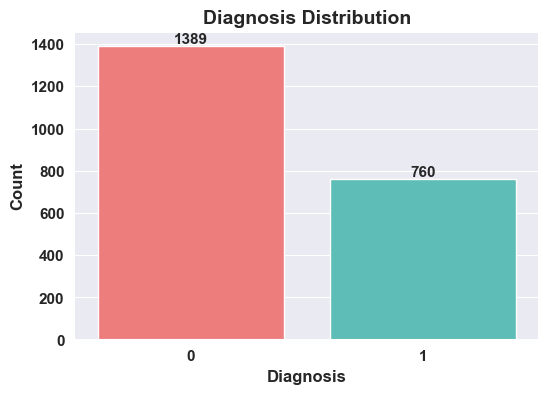

In [270]:
sns.set_style("darkgrid")
plt.figure(figsize=(6, 4))
n_classes = data['Diagnosis'].nunique()
colors = ['#FF6B6B', '#4ECDC4'][:n_classes]
ax = sns.countplot(
    x='Diagnosis',
    hue='Diagnosis',
    data=data,
    palette=colors,
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, fontsize=11, fontweight='bold')
plt.title("Diagnosis Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Diagnosis", fontsize=12, fontweight='bold')
plt.ylabel("Count", fontsize=12, fontweight='bold')
plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold')
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
plt.show()

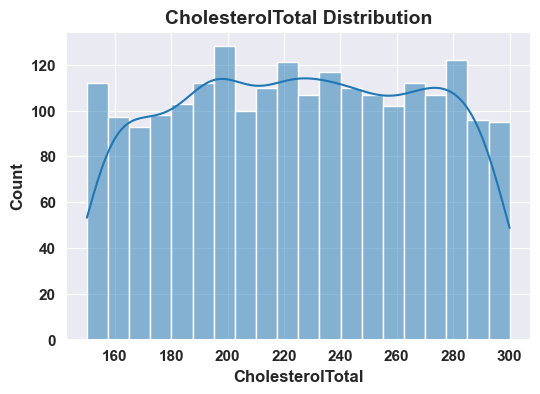

In [271]:
sns.set_style("darkgrid")
plt.figure(figsize=(6, 4))
ax = sns.histplot(
    data['CholesterolTotal'],
    bins=20,
    kde=True
)
plt.title("CholesterolTotal Distribution", fontsize=14, fontweight='bold')
plt.xlabel("CholesterolTotal", fontsize=12, fontweight='bold')
plt.ylabel("Count", fontsize=12, fontweight='bold')
plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold')
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
plt.show()

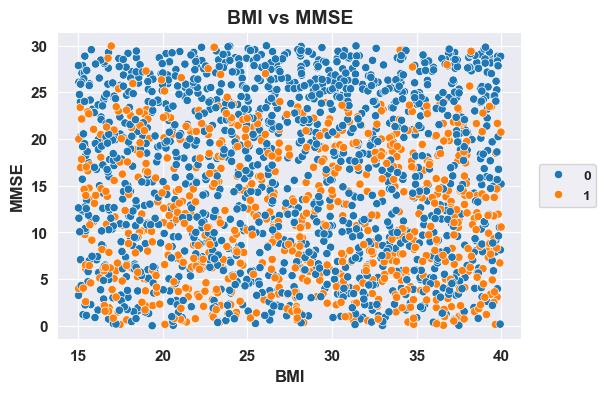

In [272]:
sns.set_style("darkgrid")
plt.figure(figsize=(6,4))
ax = sns.scatterplot(
    x=data['BMI'],
    y=data['MMSE'],
    hue=data['Diagnosis']
)
plt.title("BMI vs MMSE", fontsize=14, fontweight='bold')
plt.xlabel("BMI", fontsize=12, fontweight='bold')
plt.ylabel("MMSE", fontsize=12, fontweight='bold')
plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold')
plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left',
    prop={'weight':'bold', 'size':10}
)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
plt.show()

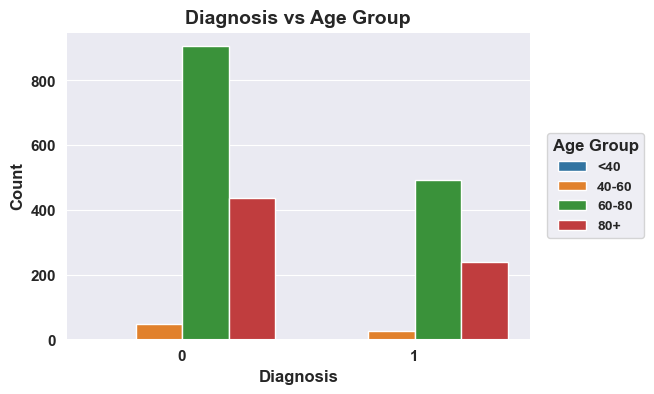

In [273]:
age_group = pd.cut(
    data['Age'],
    bins=[0, 40, 60, 80, 120],
    labels=['<40', '40-60', '60-80', '80+']
)

sns.set_style("darkgrid")
plt.figure(figsize=(6, 4))

ax = sns.countplot(
    x='Diagnosis',
    hue=age_group,
    data=data
)

plt.title("Diagnosis vs Age Group", fontsize=14, fontweight='bold')
plt.xlabel("Diagnosis", fontsize=12, fontweight='bold')
plt.ylabel("Count", fontsize=12, fontweight='bold')

plt.xticks(fontsize=11, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold')

leg = plt.legend(
    title="Age Group",
    title_fontsize=12,
    prop={'weight': 'bold', 'size': 10},
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

leg.get_title().set_fontweight('bold')

for spine in ax.spines.values():
    spine.set_linewidth(1.5)
plt.show()

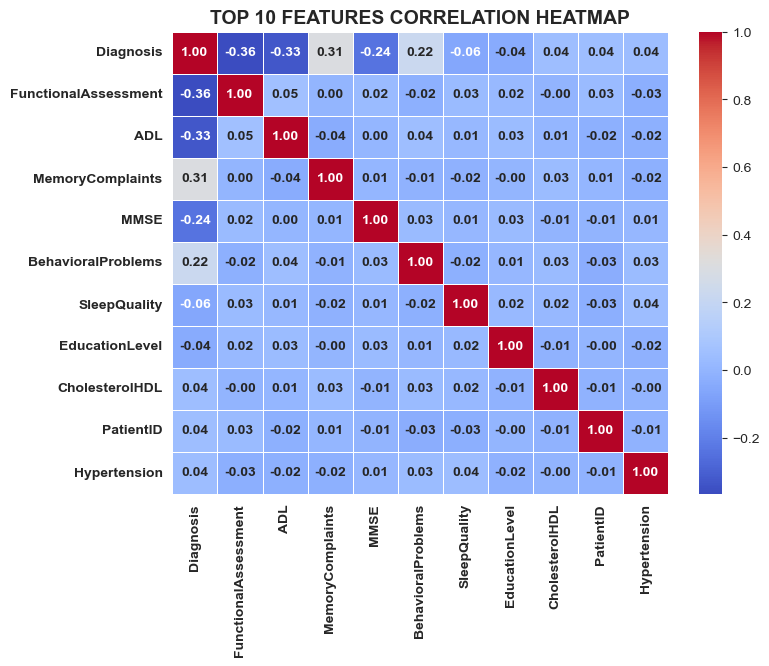

In [274]:
numeric_data = data.select_dtypes(include=['int64', 'float64'])
if 'Diagnosis' in numeric_data.columns:
    top_features = numeric_data.corr()['Diagnosis'].abs().sort_values(ascending=False).head(11).index
else:
    top_features = numeric_data.columns[:10]
top_data = numeric_data[top_features]
corr = top_data.corr()
plt.figure(figsize=(8, 6))
ax = sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5
)
for text in ax.texts:
    text.set_fontweight('bold')
    text.set_fontsize(10)
plt.title("TOP 10 FEATURES CORRELATION HEATMAP", fontsize=14, fontweight='bold')
plt.xticks(fontsize=10, fontweight='bold', rotation=90)
plt.yticks(fontsize=10, fontweight='bold', rotation=0)
plt.show()

In [275]:
data['CardiovascularDisease'].value_counts()

CardiovascularDisease
0    1839
1     310
Name: count, dtype: int64

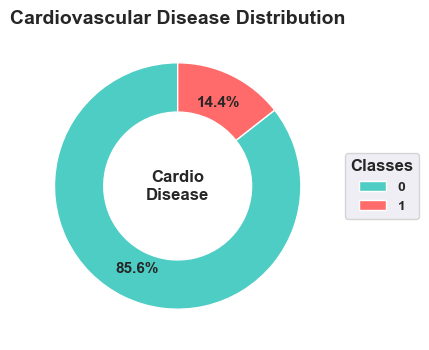

In [276]:
counts = data['CardiovascularDisease'].value_counts()
colors = ['#4ECDC4', '#FF6B6B']
plt.figure(figsize=(6,4))

wedges, texts, autotexts = plt.pie(
    counts,
    labels=None,                     
    autopct='%1.1f%%',               
    startangle=90,
    colors=colors,
    pctdistance=0.75,                
    wedgeprops={'width': 0.4},
    textprops={'fontweight': 'bold', 'fontsize': 11}
)
for t in autotexts:
    t.set_fontweight('bold')
    t.set_fontsize(11)
plt.text(
    0, 0,
    "Cardio\nDisease",
    ha='center',
    va='center',
    fontsize=12,
    fontweight='bold'
)
plt.title("Cardiovascular Disease Distribution", fontsize=14, fontweight='bold')
leg = plt.legend(
    title="Classes",
    labels=[str(i) for i in counts.index],
    bbox_to_anchor=(1.02, 0.5),
    loc='center left',
    prop={'weight': 'bold', 'size': 10},
    title_fontsize=12
)
leg.get_title().set_fontweight('bold')
plt.show()

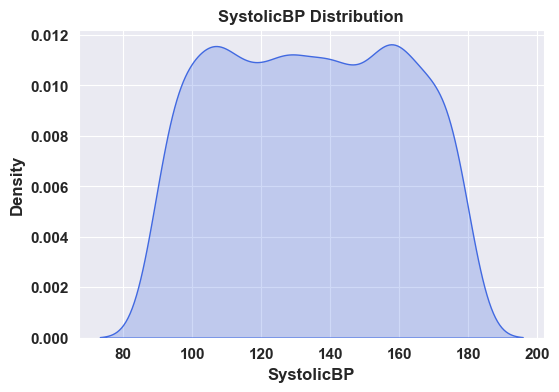

In [277]:
plt.figure(figsize=(6, 4))
sns.kdeplot(
    data=data,
    x="SystolicBP",
    fill=True,
    color="royalblue"
)
plt.title("SystolicBP Distribution", fontweight='bold')
plt.xlabel("SystolicBP", fontweight='bold', fontsize=12)
plt.ylabel("Density", fontweight='bold', fontsize=12)
plt.xticks(fontweight='bold', fontsize=11)
plt.yticks(fontweight='bold', fontsize=11)
plt.show()

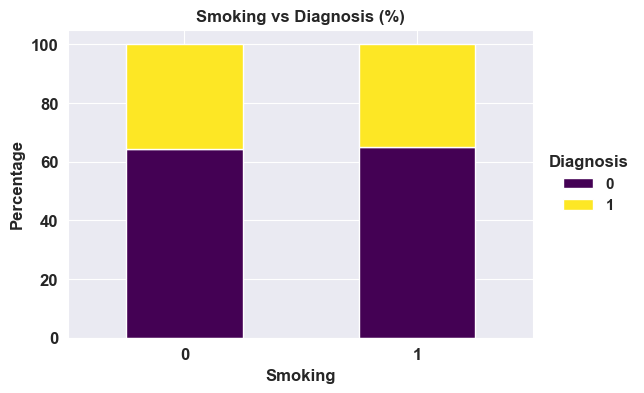

In [278]:
ct = pd.crosstab(data["Smoking"], data["Diagnosis"], normalize="index") * 100
ax = ct.plot(kind="bar", stacked=True, figsize=(6, 4), colormap="viridis")
plt.title("Smoking vs Diagnosis (%)", fontweight='bold')
plt.xlabel("Smoking", fontweight='bold', fontsize=12)
plt.ylabel("Percentage", fontweight='bold', fontsize=12)
plt.xticks(rotation=0, fontweight='bold', fontsize=12)
plt.yticks(fontweight='bold', fontsize=12)
plt.legend(
    title="Diagnosis",
    title_fontproperties={'weight': 'bold', 'size': 12},
    prop={'weight': 'bold', 'size': 11},
    bbox_to_anchor=(1.02, 0.5),
    loc='center left',
    borderaxespad=0,
    frameon=False
)
plt.show()

In [279]:
data

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,0
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,0
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,0
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,0
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,6895,61,0,0,1,39.121757,0,1.561126,4.049964,6.555306,...,0,0,4.492838,1,0,0,0,0,1,0
2145,6896,75,0,0,2,17.857903,0,18.767261,1.360667,2.904662,...,0,1,9.204952,0,0,0,0,0,1,0
2146,6897,77,0,0,1,15.476479,0,4.594670,9.886002,8.120025,...,0,0,5.036334,0,0,0,0,0,1,0
2147,6898,78,1,3,1,15.299911,0,8.674505,6.354282,1.263427,...,0,0,3.785399,0,0,0,0,1,1,0


# OUTLIER DETECTION

In [280]:
data_clean = data.copy()
numeric_cols = data_clean.select_dtypes(include=np.number).columns
threshold = 3
data_before = data_clean[numeric_cols].copy()
outlier_mask = pd.DataFrame(
    False,
    index=data_clean.index,
    columns=numeric_cols
)
for col in numeric_cols:
    z_scores = np.abs(stats.zscore(data_clean[col]))
    outlier_mask[col] = z_scores > threshold
    mean_val = data_clean[col].mean()
    std_val  = data_clean[col].std()
    upper_limit = mean_val + threshold * std_val
    lower_limit = mean_val - threshold * std_val
    data_clean[col] = np.where(
        data_clean[col] > upper_limit,
        upper_limit,
        np.where(
            data_clean[col] < lower_limit,
            lower_limit,
            data_clean[col]
        )
    )
print("===== OUTLIER TREATMENT REPORT =====\n")
for col in numeric_cols:
    num_outliers = outlier_mask[col].sum()
    print(f"{col} : {num_outliers} outliers treated")
print("\nFinal Shape :", data_clean.shape)

===== OUTLIER TREATMENT REPORT =====

PatientID : 0 outliers treated
Age : 0 outliers treated
Gender : 0 outliers treated
Ethnicity : 0 outliers treated
EducationLevel : 0 outliers treated
BMI : 0 outliers treated
Smoking : 0 outliers treated
AlcoholConsumption : 0 outliers treated
PhysicalActivity : 0 outliers treated
DietQuality : 0 outliers treated
SleepQuality : 0 outliers treated
FamilyHistoryAlzheimers : 0 outliers treated
CardiovascularDisease : 0 outliers treated
Diabetes : 0 outliers treated
Depression : 0 outliers treated
HeadInjury : 199 outliers treated
Hypertension : 0 outliers treated
SystolicBP : 0 outliers treated
DiastolicBP : 0 outliers treated
CholesterolTotal : 0 outliers treated
CholesterolLDL : 0 outliers treated
CholesterolHDL : 0 outliers treated
CholesterolTriglycerides : 0 outliers treated
MMSE : 0 outliers treated
FunctionalAssessment : 0 outliers treated
MemoryComplaints : 0 outliers treated
BehavioralProblems : 0 outliers treated
ADL : 0 outliers treated
Co

In [281]:
data_clean.head()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751.0,73.0,0.0,0.0,2.0,22.927749,0.0,13.297218,6.327112,1.347214,...,0.0,0.0,1.725883,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,4752.0,89.0,0.0,0.0,0.0,26.827681,0.0,4.542524,7.619885,0.518767,...,0.0,0.0,2.592424,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,4753.0,73.0,0.0,3.0,1.0,17.795882,0.0,19.555085,7.844988,1.826335,...,0.0,0.0,7.119548,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,4754.0,74.0,1.0,0.0,1.0,33.800817,1.0,12.209266,8.428001,7.435604,...,0.0,1.0,6.481226,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4755.0,89.0,0.0,0.0,0.0,20.716974,0.0,18.454356,6.310461,0.795498,...,0.0,0.0,0.014691,0.0,0.0,1.0,1.0,0.0,0.0,0.0


# TRAIN & TEST SPLIT 

In [282]:
X = data_clean.drop(columns=['Diagnosis'])
y = data_clean['Diagnosis']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1719, 34)
X_test shape: (430, 34)
y_train shape: (1719,)
y_test shape: (430,)


# Mutual Information-Based Feature Selection

In [283]:
mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)
selector = SelectKBest(
    score_func=mutual_info_classif,
    k=20
)
X_train_selected = selector.fit_transform(
    X_train,
    y_train
)
X_test_selected = selector.transform(X_test)
selected_feature_names = X_train.columns[
    selector.get_support()
]
X_train_selected = pd.DataFrame(
    X_train_selected,
    columns=selected_feature_names
)
X_test_selected = pd.DataFrame(
    X_test_selected,
    columns=selected_feature_names
)
scaler = StandardScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train_selected),
    columns=selected_feature_names
)
X_test = pd.DataFrame(
    scaler.transform(X_test_selected),
    columns=selected_feature_names
)
print("Final Train Shape :", X_train.shape)
print("Final Test Shape  :", X_test.shape)

Final Train Shape : (1719, 20)
Final Test Shape  : (430, 20)


In [284]:
mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)
mi_df = pd.DataFrame({

    'Feature': X_train.columns,

    'MI_Score': mi_scores
})

mi_df = mi_df.sort_values(

    by='MI_Score',

    ascending=False
)
print("\n================================================")
print("MUTUAL INFORMATION FEATURE SCORES")
print("================================================")
print(mi_df)
TOP_K_FEATURES = 20
selector = SelectKBest(
    score_func=mutual_info_classif,
    k=TOP_K_FEATURES
)
X_train_selected = selector.fit_transform(
    X_train,
    y_train
)
X_test_selected = selector.transform(
    X_test
)

selected_feature_names = X_train.columns[
    selector.get_support()
]

print("SELECTED ORIGINAL FEATURE NAMES:")

for i, feature in enumerate(
    selected_feature_names,
    start=1
):

    print(f"{i}. {feature}")
X_train_selected = pd.DataFrame(
    X_train_selected,
    columns=selected_feature_names
)
X_test_selected = pd.DataFrame(

    X_test_selected,

    columns=selected_feature_names
)
print("FINAL FEATURE SELECTION OUTPUT:")
print("Selected X_train Shape :", X_train_selected.shape)
print("Selected X_test Shape  :", X_test_selected.shape)


MUTUAL INFORMATION FEATURE SCORES
                      Feature  MI_Score
14       FunctionalAssessment  0.086064
17                        ADL  0.077301
13                       MMSE  0.067915
15           MemoryComplaints  0.042507
16         BehavioralProblems  0.016645
9                  SystolicBP  0.013007
0                   PatientID  0.012914
2          AlcoholConsumption  0.011914
5     FamilyHistoryAlzheimers  0.011314
12             CholesterolHDL  0.009035
10           CholesterolTotal  0.008191
4                SleepQuality  0.005811
3                 DietQuality  0.005413
11             CholesterolLDL  0.001542
1                   Ethnicity  0.000000
8                Hypertension  0.000000
7                  Depression  0.000000
6       CardiovascularDisease  0.000000
18                  Confusion  0.000000
19  DifficultyCompletingTasks  0.000000
SELECTED ORIGINAL FEATURE NAMES:
1. PatientID
2. Ethnicity
3. AlcoholConsumption
4. DietQuality
5. SleepQuality
6. FamilyHist

# FEATURE IMPORTANCE

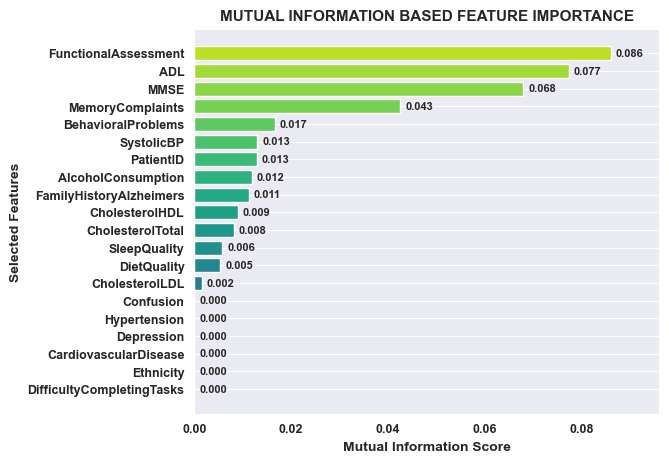

Selected Feature Shape : (2149, 20)
Target Shape : (2149,)

Training Data Shape
X_train : (1719, 20)
y_train : (1719,)

Testing Data Shape
X_test : (430, 20)
y_test : (430,)


In [285]:
X_train = X_train_selected
X_test = X_test_selected

feature_importance_df = pd.DataFrame({
    'Feature': selected_feature_names,
    'MI_Score': mi_scores[
        selector.get_support()
    ]
})
feature_importance_df = feature_importance_df.sort_values(
    by='MI_Score',
    ascending=True
)
plt.figure(figsize=(6, 5))
cmap = plt.cm.viridis   
colors = cmap(
    np.linspace(
        0.2,
        0.9,
        len(feature_importance_df)
    )
)

bars = plt.barh(

    feature_importance_df['Feature'],

    feature_importance_df['MI_Score'],

    color=colors
)
for bar in bars:

    width = bar.get_width()

    plt.text(

        width + 0.001,

        bar.get_y() + bar.get_height()/2,

        f'{width:.3f}',

        va='center',

        fontsize=8,

        fontweight='bold'
    )
plt.xlabel(
    "Mutual Information Score",
    fontsize=10,
    fontweight='bold'
)
plt.ylabel(
    "Selected Features",
    fontsize=10,
    fontweight='bold'
)

plt.title(
    "MUTUAL INFORMATION BASED FEATURE IMPORTANCE",
    fontsize=11,
    fontweight='bold'
)

plt.xticks(
    fontsize=9,
    fontweight='bold'
)

plt.yticks(
    fontsize=9,
    fontweight='bold'
)
plt.grid(axis='x')
plt.xlim(0.00, 0.096)
plt.show()

selected_features = feature_importance_df['Feature'].values
X_selected = data_clean[selected_features]
y = data_clean['Diagnosis']
print("Selected Feature Shape :", X_selected.shape)
print("Target Shape :", y.shape)


X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("\nTraining Data Shape")
print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("\nTesting Data Shape")
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

In [286]:
import joblib
joblib.dump(scaler, "scaler.pkl")
joblib.dump(label_encoders, "encoder.pkl")
joblib.dump(selected_feature_names.tolist(), "selected_features.pkl")
print("Scaler saved as scaler.pkl")
print("Selector saved as encoder.pkl")
print("Selected feature names saved as selected_features.pkl")

Scaler saved as scaler.pkl
Selector saved as encoder.pkl
Selected feature names saved as selected_features.pkl


In [32]:
X_selected.head()

,Gender,Ethnicity,Disorientation,Hypertension,SystolicBP,DiastolicBP,CholesterolLDL,DoctorInCharge,DietQuality,SleepQuality,CholesterolTotal,CholesterolHDL,Forgetfulness,AlcoholConsumption,PatientID,BehavioralProblems,MemoryComplaints,MMSE,ADL,FunctionalAssessment
0,0.0,0.0,0.0,0.0,142.0,72.0,56.150897,0.0,1.347214,9.025679,242.366840,33.682563,0.0,13.297218,4751.0,0.0,0.0,21.463532,1.725883,6.518877
1,0.0,0.0,0.0,0.0,115.0,64.0,193.407996,0.0,0.518767,7.151293,231.162595,79.028477,1.0,4.542524,4752.0,0.0,0.0,20.613267,2.592424,7.118696
2,0.0,3.0,1.0,0.0,99.0,116.0,153.322762,0.0,1.826335,9.673574,284.181858,69.772292,0.0,19.555085,4753.0,0.0,0.0,7.356249,7.119548,5.895077
3,1.0,0.0,0.0,0.0,118.0,115.0,65.366637,0.0,7.435604,8.392554,159.582240,68.457491,0.0,12.209266,4754.0,1.0,0.0,13.991127,6.481226,8.965106
4,0.0,0.0,0.0,0.0,94.0,117.0,92.869700,0.0,0.795498,5.597238,237.602184,56.874305,0.0,18.454356,4755.0,0.0,0.0,13.517609,0.014691,6.045039


In [154]:
input_dim = X_train.shape[1]
num_classes = len(np.unique(y_train))
embedding_dim = 8
y_train = np.asarray(y_train).astype(np.int32)
y_test = np.asarray(y_test).astype(np.int32)
y_train_in = y_train.reshape(-1, 1)
y_test_in = y_test.reshape(-1, 1)

In [155]:
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps

In [156]:
class KLDivergenceLayer(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        kl = -0.5 * tf.reduce_mean(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
        )
        entropy_bonus = tf.reduce_mean(tf.math.log(tf.math.abs(z_mean) + 1e-6))
        total = kl - 0.001 * entropy_bonus
        self.add_loss(total)
        return z_mean, z_log_var

In [157]:
class SparseSelfAttention(layers.Layer):
    def __init__(self, dim, heads=2):
        super().__init__()
        self.attn = layers.MultiHeadAttention(num_heads=heads, key_dim=dim)
        self.norm = layers.LayerNormalization()

    def call(self, x):
        x_seq = tf.expand_dims(x, axis=1)
        attn_out = self.attn(x_seq, x_seq)
        out = self.norm(x_seq + attn_out)
        return tf.squeeze(out, axis=1)

In [158]:
class RSPBlock(layers.Layer):
    def __init__(self, units):
        super().__init__()
        self.d1 = layers.Dense(units, activation='relu',
                                kernel_regularizer=regularizers.l2(1e-4))
        self.d2 = layers.Dense(units)
        self.proj = layers.Dense(units)
        self.norm = layers.LayerNormalization()
        self.drop = layers.Dropout(0.2)

    def call(self, x):
        skip = self.proj(x)
        h = self.d1(x)
        h = self.drop(h)
        h = self.d2(h)
        return self.norm(skip + h)

In [159]:
def build_encoder(input_dim, latent_dim):

    feature_input = layers.Input(shape=(input_dim,))
    label_input = layers.Input(shape=(1,), dtype='int32')

    label_emb = layers.Embedding(num_classes, embedding_dim)(label_input)
    label_emb = layers.Flatten()(label_emb)

    x = layers.Concatenate()([feature_input, label_emb])

    x = layers.Dense(64, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Dense(32, activation='relu')(x)

    x = SparseSelfAttention(32)(x)

    z_mean = layers.Dense(latent_dim)(x)
    z_log_var = layers.Dense(latent_dim)(x)

    return models.Model(
        [feature_input, label_input],
        [z_mean, z_log_var],
        name="Encoder"
    )

In [160]:
def build_model(params):

    latent_dim, rsp_layers, lr, dropout, num_heads = params

    latent_dim = int(latent_dim)
    rsp_layers = int(rsp_layers)
    num_heads = int(num_heads)

    feature_input = layers.Input(shape=(input_dim,))
    label_input = layers.Input(shape=(1,), dtype='int32')

    encoder = build_encoder(input_dim, latent_dim)

    z_mean, z_log_var = encoder([feature_input, label_input])
    z_mean, z_log_var = KLDivergenceLayer()([z_mean, z_log_var])

    z = Sampling()([z_mean, z_log_var])

    x = layers.Concatenate()([feature_input, z])

    x = layers.Dense(32, activation='relu')(x)
    x = layers.BatchNormalization()(x)

    for _ in range(rsp_layers):
        x = RSPBlock(16)(x)

    x = SparseSelfAttention(16, heads=num_heads)(x)

    x = layers.Dropout(dropout)(x)

    x = layers.Dense(16, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    output = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model([feature_input, label_input], output)

    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr, clipnorm=1.0),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
class BobcatOptimizationAlgorithm:
    def __init__(

        self,
        objective_function,
        bounds,
        n_bobcats=50,
        max_iterations=30,
        alpha=0.2,
        beta=0.5,
        gamma=1.5
    ):

        self.objective_function = objective_function
        self.bounds = bounds
        self.n_bobcats = n_bobcats
        self.max_iterations = max_iterations

        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma

        self.best_position = None
        self.best_fitness = float('inf')

        self.convergence_curve = []

    def initialize_population(self):

        population = []

        for _ in range(self.n_bobcats):

            position = []

            for min_val, max_val in self.bounds:

                if isinstance(min_val, int):

                    value = np.random.randint(min_val, max_val + 1)

                else:

                    value = np.random.uniform(min_val, max_val)

                position.append(value)

            population.append(position)

        return np.array(population)

    def silent_hunting(self, position):

        new_position = position.copy()

        for i in range(len(position)):

            step = self.alpha * np.random.randn()

            new_position[i] = np.clip(
                position[i] + step,
                self.bounds[i][0],
                self.bounds[i][1]
            )

        return new_position

    def intelligent_tracking(self, position, best_position):

        new_position = position.copy()

        for i in range(len(position)):

            move = self.beta * np.random.random() * (
                best_position[i] - position[i]
            )

            new_position[i] = np.clip(
                position[i] + move,
                self.bounds[i][0],
                self.bounds[i][1]
            )

        return new_position
    def aggressive_jump_attack(self, position, global_best):

        new_position = position.copy()

        for i in range(len(position)):

            jump = self.gamma * np.random.random() * (
                global_best[i] - position[i]
            )

            new_position[i] = np.clip(
                position[i] + jump,
                self.bounds[i][0],
                self.bounds[i][1]
            )

        return new_position

    def optimize(self):

        population = self.initialize_population()

        fitness = np.array([
            self.objective_function(ind)
            for ind in population
        ])

        best_idx = np.argmin(fitness)

        self.best_position = population[best_idx]
        self.best_fitness = fitness[best_idx]

        self.convergence_curve.append(self.best_fitness)

        for iteration in range(self.max_iterations):

            new_population = []

            for i in range(self.n_bobcats):
                if i < self.n_bobcats // 3:

                    new_pos = self.silent_hunting(population[i])

                elif i < 2 * self.n_bobcats // 3:

                    new_pos = self.intelligent_tracking(
                        population[i],
                        self.best_position
                    )

                else:

                    new_pos = self.aggressive_jump_attack(
                        population[i],
                        self.best_position
                    )

                new_population.append(new_pos)

            new_population = np.array(new_population)
            new_fitness = np.array([
                self.objective_function(ind)
                for ind in new_population
            ])

            current_best_idx = np.argmin(new_fitness)
            if new_fitness[current_best_idx] < self.best_fitness:

                self.best_fitness = new_fitness[current_best_idx]
                self.best_position = new_population[current_best_idx]

            population = new_population
            self.convergence_curve.append(self.best_fitness)
            print(
                f"Iteration {iteration + 1} "
                f"| Best Fitness: {self.best_fitness:.6f}"
            )

        print("\n================ BOA FINISHED ================\n")

        return (
            self.best_position,
            self.best_fitness,
            self.convergence_curve
        )

In [ ]:
def objective_function(params):

    model = build_model(params)

    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train,
        test_size=0.2,
        stratify=y_train
    )

    y_tr_in = y_tr.reshape(-1, 1)
    y_val_in = y_val.reshape(-1, 1)

    early = EarlyStopping(
        monitor='val_accuracy',
        patience=2,
        restore_best_weights=True
    )

    history = model.fit(
        [X_tr, y_tr_in], y_tr,
        validation_data=([X_val, y_val_in], y_val),
        epochs=5,
        batch_size=64,
        verbose=0,
        callbacks=[early]
    )

    val_acc = max(history.history['val_accuracy'])

    tf.keras.backend.clear_session()

    return val_acc

In [ ]:
bounds = [
    (16, 64),      
    (1, 3),        
    (1e-4, 5e-4),  
    (0.2, 0.5),    
    (1, 4)        
]
boa = BobcatOptimizationAlgorithm(
    objective_function,
    bounds,
    n_bobcats=50,
    max_iterations=30
)

best_params, best_fitness, curve = boa.optimize()

Iteration 1 | Best Fitness: 0.645349
Iteration 2 | Best Fitness: 0.645349
Iteration 3 | Best Fitness: 0.645349

================ BOA FINISHED ================



In [1]:
final_model = build_model(best_params)
print("Best Parameters:")
print("Latent Dimension:", int(best_params[0]))
print("RSP Layers:", int(best_params[1]))
print("Learning Rate:", round(float(best_params[2]), 6))
print("Dropout Rate:", round(float(best_params[3]), 4))
print("Attention Heads:", int(best_params[4]))

Best Parameters:
Latent Dimension: 41
RSP Layers: 3
Learning Rate: 0.000492
Dropout Rate: 0.483
Attention Heads: 1


In [ ]:
final_model = build_model(best_params)
print("\nFinal Model Summary:")
final_model.summary()
history = final_model.fit(
    [X_train, y_train_in], y_train,
    validation_data=([X_test, y_test_in], y_test),
    epochs=50,
    batch_size=64,
    verbose=1)

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.4789 - loss: 1.8985 - val_accuracy: 0.6395 - val_loss: 1.5032
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5651 - loss: 1.5015 - val_accuracy: 0.6605 - val_loss: 1.2188
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5977 - loss: 1.2363 - val_accuracy: 0.6395 - val_loss: 1.0175
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5885 - loss: 1.0675 - val_accuracy: 0.6605 - val_loss: 0.8488
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5965 - loss: 0.9315 - val_accuracy: 0.6884 - val_loss: 0.7448
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6338 - loss: 0.8153 - val_accuracy: 0.7000 - val_loss: 0.6908
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6319 - loss: 0.7798 - val_accuracy: 0.7023 - val_loss: 0.6453
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6650 - loss: 0.7155 - val_accuracy: 0.7535 - v

In [204]:
y_prob = final_model.predict([X_test, y_test_in])
y_pred = np.argmax(y_prob, axis=1)
print("\nCLASSIFICATION REPORT:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_.astype(str),
    digits=4
))

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

CLASSIFICATION REPORT:

              precision    recall  f1-score   support

         0.0     0.9928    0.9964    0.9946       278
         1.0     0.9934    0.9868    0.9901       152

    accuracy                         0.9930       430
   macro avg     0.9931    0.9916    0.9924       430
weighted avg     0.9930    0.9930    0.9930       430



# MODEL TRAINING PLOT FOR ACCURACY AND LOSS

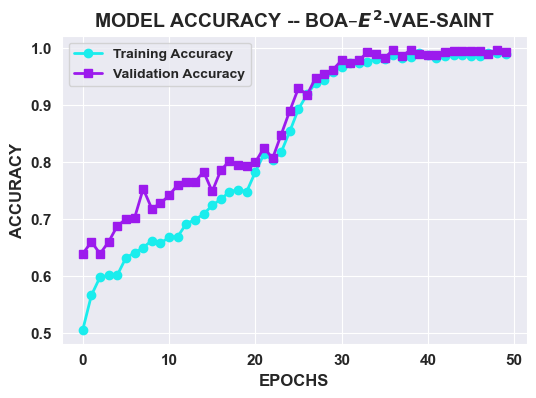

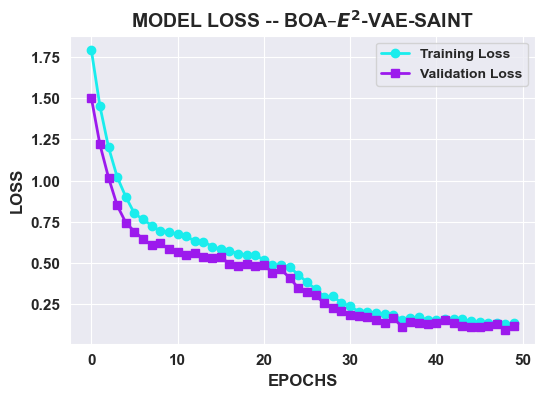

In [205]:
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'
plt.figure(figsize=(6, 4))
plt.plot(
    history.history['accuracy'],
    linewidth=2,
    color='#1AEDED',
    marker='o',
    markersize=6,
    label='Training Accuracy'
)
plt.plot(
    history.history['val_accuracy'],
    linewidth=2,
    color='#9C1AED',
    marker='s',
    markersize=6,
    label='Validation Accuracy'
)
plt.title(
    'MODEL ACCURACY -- BOA–$E^2$-VAE-SAINT',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel(
    'EPOCHS',
    fontsize=12,
    fontweight='bold'
)
plt.ylabel(
    'ACCURACY',
    fontsize=12,
    fontweight='bold'
)
plt.xticks(
    fontsize=11,
    fontweight='bold'
)
plt.yticks(
    fontsize=11,
    fontweight='bold'
)
legend = plt.legend(
    fontsize=10
)
for text in legend.get_texts():
    text.set_fontweight('bold')
plt.grid(True)
plt.show()


plt.figure(figsize=(6, 4))
plt.plot(
    history.history['loss'],
    linewidth=2,
    color='#1AEDED',
    marker='o',
    markersize=6,
    label='Training Loss'
)
plt.plot(
    history.history['val_loss'],
    linewidth=2,
    color='#9C1AED',
    marker='s',
    markersize=6,
    label='Validation Loss'
)
plt.title(
    'MODEL LOSS -- BOA–$E^2$-VAE-SAINT',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel(
    'EPOCHS',
    fontsize=12,
    fontweight='bold'
)
plt.ylabel(
    'LOSS',
    fontsize=12,
    fontweight='bold'
)
plt.xticks(
    fontsize=11,
    fontweight='bold'
)
plt.yticks(
    fontsize=11,
    fontweight='bold'
)
legend = plt.legend(
    fontsize=10
)
for text in legend.get_texts():
    text.set_fontweight('bold')
plt.grid(True)
plt.show()

In [215]:
y_prob = final_model.predict([X_test, y_test_in], verbose=0)
test_pred = np.argmax(y_prob, axis=1)
accuracy = accuracy_score(y_test, test_pred)
precision_macro = precision_score(
    y_test,
    test_pred,
    average='macro'
)

recall_macro = recall_score(
    y_test,
    test_pred,
    average='macro'
)

f1_macro = f1_score(
    y_test,
    test_pred,
    average='macro'
)
balanced_acc = balanced_accuracy_score(y_test, test_pred)

mcc = matthews_corrcoef(y_test, test_pred)
cm = confusion_matrix(y_test, test_pred)
tn = cm[0, 0]
fp = cm[0, 1]
fn = cm[1, 0]
tp = cm[1, 1]
specificity = tn / (tn + fp + 1e-8)
sensitivity = tp / (tp + fn + 1e-8)
print("\nCLASSIFICATION METRICS -- BOA–E2-VAE-SAINT\n")

print(f"Accuracy        : {accuracy:.4f}")
print(f"Precision       : {precision_macro:.4f}")
print(f"Recall          : {recall_macro:.4f}")
print(f"F1-score        : {f1_macro:.4f}")
print(f"Specificity     : {specificity:.4f}")
print(f"Sensitivity     : {sensitivity:.4f}")
print(f"Balanced Acc    : {balanced_acc:.4f}")
print(f"MCC             : {mcc:.4f}")


CLASSIFICATION METRICS -- BOA–E2-VAE-SAINT

Accuracy        : 0.9930
Precision       : 0.9947
Recall          : 0.9901
F1-score        : 0.9923
Specificity     : 1.0000
Sensitivity     : 0.9803
Balanced Acc    : 0.9901
MCC             : 0.9848


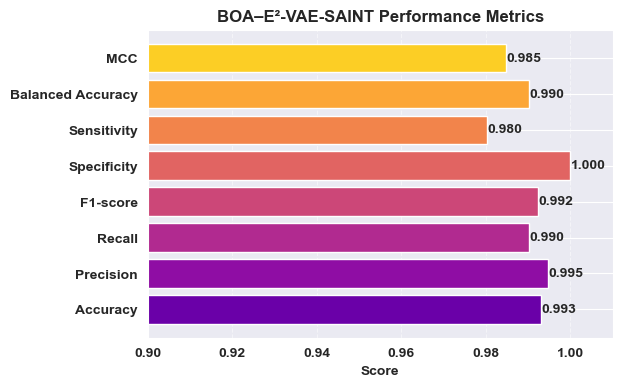

In [216]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision_macro,
    "Recall": recall_macro,
    "F1-score": f1_macro,
    "Specificity": specificity,
    "Sensitivity": sensitivity,
    "Balanced Accuracy": balanced_acc,
    "MCC": mcc
}
names = list(metrics.keys())
values = list(metrics.values())
cmap = plt.cm.plasma
colors = cmap(np.linspace(0.2, 0.9, len(values)))
plt.figure(figsize=(6, 4))
bars = plt.barh(names, values, color=colors)
plt.xlabel("Score")
plt.title("BOA–E²-VAE-SAINT Performance Metrics")
plt.xlim(0.90, 1.01)
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.0001,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.3f}",
        va='center'
    )
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

# CONFUSION MATRIX

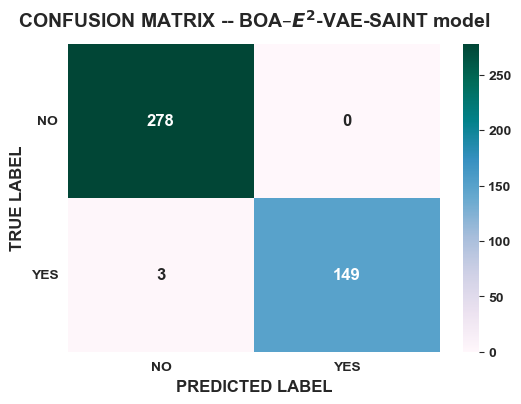

In [217]:
cm = confusion_matrix(
    y_test,
    test_pred
)
class_names = ['NO', 'YES']
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='PuBuGn',
    cbar=True,
    annot_kws={
        'weight': 'bold',
        'size': 12
    }
)

plt.title(
    'CONFUSION MATRIX -- BOA–$E^2$-VAE-SAINT model',
    fontsize=14,
    fontweight='bold',
    pad=12
)
plt.xlabel(
    'PREDICTED LABEL',
    fontsize=12,
    fontweight='bold'
)
plt.ylabel(
    'TRUE LABEL',
    fontsize=12,
    fontweight='bold'
)
plt.xticks(
    ticks=[0.5, 1.5],
    labels=class_names,
    fontsize=10,
    fontweight='bold'
)
plt.yticks(
    ticks=[0.5, 1.5],
    labels=class_names,
    fontsize=10,
    fontweight='bold',
    rotation=0
)
plt.show()

# ROC CURVE

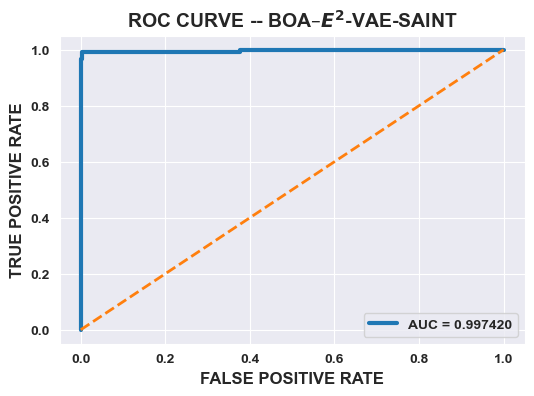

In [218]:
plt.figure(figsize=(6, 4))
y_score = test_pred_prob[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, linewidth=3, label=f'AUC = {roc_auc:.6f}')
plt.plot([0, 1], [0, 1], linestyle='--', linewidth=2)
plt.title(r'ROC CURVE -- BOA–$E^2$-VAE-SAINT',
          fontsize=14,
          fontweight='bold')

plt.xlabel('FALSE POSITIVE RATE', fontsize=12, fontweight='bold')
plt.ylabel('TRUE POSITIVE RATE', fontsize=12, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# PRECISION-RECALL CURVE

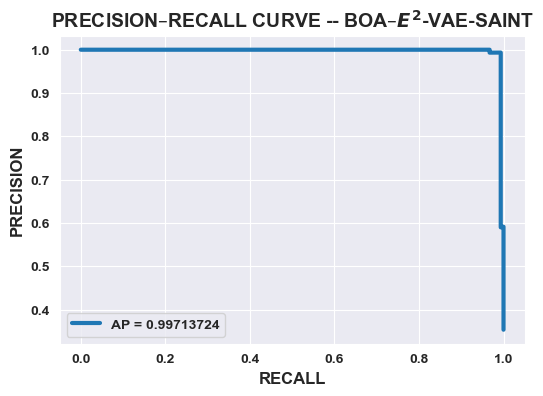

In [219]:
plt.figure(figsize=(6, 4))
y_score = test_pred_prob[:, 1]
precision, recall, _ = precision_recall_curve(y_test, y_score)
avg_precision = average_precision_score(y_test, y_score)
plt.plot(
    recall,
    precision,
    linewidth=3,
    label=f'AP = {avg_precision:.8f}'
)
plt.title(
    r'PRECISION–RECALL CURVE -- BOA–$E^2$-VAE-SAINT',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('RECALL', fontsize=12, fontweight='bold')
plt.ylabel('PRECISION', fontsize=12, fontweight='bold')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

# SAVE THE MODEL 

In [234]:
final_model.save("EEVAE_SISA_BOA_model.h5")
print("Model saved successfully as EEVAE_SISA_BOA_model.h5")

Model saved successfully as EEVAE_SISA_BOA_model.h5


# SELECTED FEATURE VALUES 

In [245]:
row_index = 190 
sample = data_clean.loc[row_index, selected_feature_names]
label = data_clean.loc[row_index, 'Diagnosis']
print("FEATURE VALUES:")
print(sample)
print("\nDIAGNOSIS:")
print(label)

FEATURE VALUES:
PatientID               4941.000000
Gender                     1.000000
Ethnicity                  3.000000
AlcoholConsumption        18.444352
DietQuality                4.959918
SleepQuality               8.063561
Hypertension               0.000000
SystolicBP               114.000000
DiastolicBP               84.000000
CholesterolTotal         202.118533
CholesterolLDL           190.345523
CholesterolHDL            60.312477
MMSE                      16.561407
FunctionalAssessment       5.803626
MemoryComplaints           0.000000
BehavioralProblems         0.000000
ADL                        7.738045
Disorientation             0.000000
Forgetfulness              1.000000
DoctorInCharge             0.000000
Name: 190, dtype: float64

DIAGNOSIS:
0.0


In [316]:
row_index = 50 
sample = data_clean.loc[row_index, selected_feature_names]
label = data_clean.loc[row_index, 'Diagnosis']
print("FEATURE VALUES:")
print(sample)
print("\nDIAGNOSIS:")
print(label)

FEATURE VALUES:
PatientID                    4801.000000
Ethnicity                       2.000000
AlcoholConsumption             15.649190
DietQuality                     0.161403
SleepQuality                    8.353761
FamilyHistoryAlzheimers         0.000000
CardiovascularDisease           0.000000
Depression                      0.000000
Hypertension                    0.000000
SystolicBP                    162.000000
CholesterolTotal              257.165430
CholesterolLDL                153.473133
CholesterolHDL                 47.714131
MMSE                           14.745244
FunctionalAssessment            0.222116
MemoryComplaints                1.000000
BehavioralProblems              0.000000
ADL                             4.423271
Confusion                       0.000000
DifficultyCompletingTasks       0.000000
Name: 50, dtype: float64

DIAGNOSIS:
1.0


In [308]:
row_index = 250 
sample = data_clean.loc[row_index, selected_feature_names]
label = data_clean.loc[row_index, 'Diagnosis']
print("FEATURE VALUES:")
print(sample)
print("\nDIAGNOSIS:")
print(label)

FEATURE VALUES:
PatientID                    5001.000000
Ethnicity                       0.000000
AlcoholConsumption             16.119067
DietQuality                     7.361613
SleepQuality                    5.206453
FamilyHistoryAlzheimers         0.000000
CardiovascularDisease           0.000000
Depression                      0.000000
Hypertension                    0.000000
SystolicBP                     99.000000
CholesterolTotal              188.071193
CholesterolLDL                193.945720
CholesterolHDL                 77.910309
MMSE                           17.683374
FunctionalAssessment            0.020428
MemoryComplaints                0.000000
BehavioralProblems              0.000000
ADL                             1.704989
Confusion                       0.000000
DifficultyCompletingTasks       0.000000
Name: 250, dtype: float64

DIAGNOSIS:
1.0


# PREDICTION

In [309]:
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps


class KLDivergenceLayer(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs

        kl = -0.5 * tf.reduce_mean(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)
        )

        self.add_loss(kl)
        return z_mean, z_log_var


class SparseSelfAttention(layers.Layer):
    def __init__(self, dim=32, heads=2, **kwargs):
        super().__init__(**kwargs)
        self.attn = layers.MultiHeadAttention(num_heads=heads, key_dim=dim)
        self.norm = layers.LayerNormalization()

    def call(self, x):
        x_seq = tf.expand_dims(x, axis=1)
        attn_out = self.attn(x_seq, x_seq)
        out = self.norm(x_seq + attn_out)
        return tf.squeeze(out, axis=1)


class RSPBlock(layers.Layer):
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.d1 = layers.Dense(units, activation='relu',
                               kernel_regularizer=regularizers.l2(1e-4))
        self.d2 = layers.Dense(units)
        self.proj = layers.Dense(units)
        self.norm = layers.LayerNormalization()

    def call(self, x):
        skip = self.proj(x)
        h = self.d1(x)
        h = self.d2(h)
        return self.norm(skip + h)

In [310]:
model = tf.keras.models.load_model(
    "EEVAE_SISA_BOA_model.h5",
    custom_objects={
        "Sampling": Sampling,
        "KLDivergenceLayer": KLDivergenceLayer,
        "SparseSelfAttention": SparseSelfAttention,
        "RSPBlock": RSPBlock
    },
    compile=False
)

print("Model Loaded Successfully")

Model Loaded Successfully


In [311]:
import numpy as np
import pandas as pd

new_patient = {
    "PatientID": 4941.0,
    "Gender": 1.0,
    "Ethnicity": 3.0,
    "AlcoholConsumption": 18.444352,
    "DietQuality": 4.959918,
    "SleepQuality": 8.063561,
    "Hypertension": 0.0,
    "SystolicBP": 114.0,
    "DiastolicBP": 84.0,
    "CholesterolTotal": 202.118533,
    "CholesterolLDL": 190.345523,
    "CholesterolHDL": 60.312477,
    "MMSE": 16.561407,
    "FunctionalAssessment": 5.803626,
    "MemoryComplaints": 0.0,
    "BehavioralProblems": 0.0,
    "ADL": 7.738045,
    "Disorientation": 0.0,
    "Forgetfulness": 1.0,
    "DoctorInCharge": 0.0
}

input_df = pd.DataFrame([new_patient])

input_df = input_df.reindex(columns=scaler.feature_names_in_, fill_value=0)

print("\nINPUT DATA (Aligned)")
print(input_df)

input_scaled = scaler.transform(input_df)
input_scaled = np.asarray(input_scaled, dtype=np.float32)
print("\nScaled shape:", input_scaled.shape)

label_input = np.zeros((1, 1), dtype=np.int32)

prediction = model.predict([input_scaled, label_input], verbose=0)

prob_normal = prediction[0][0]
prob_alzheimer = prediction[0][1]

threshold = 0.5

if prob_alzheimer >= threshold:
    result = "Alzheimer's Disease"
    predicted_class = 1
else:
    result = "Normal"
    predicted_class = 0

confidence = max(prob_normal, prob_alzheimer) * 100

print("\n========================================")
print("ALZHEIMER DISEASE PREDICTION RESULT")
print("========================================")

print(f"Prediction : {result}")
print(f"Confidence : {confidence:.2f}%")

print("\nClass Probabilities:")
print(f"Normal      : {prob_normal:.4f}")
print(f"Alzheimer's : {prob_alzheimer:.4f}")


INPUT DATA (Aligned)
   PatientID  Ethnicity  AlcoholConsumption  DietQuality  SleepQuality  \
0     4941.0        3.0           18.444352     4.959918      8.063561   

   FamilyHistoryAlzheimers  CardiovascularDisease  Depression  Hypertension  \
0                        0                      0           0           0.0   

   SystolicBP  CholesterolTotal  CholesterolLDL  CholesterolHDL       MMSE  \
0       114.0        202.118533      190.345523       60.312477  16.561407   

   FunctionalAssessment  MemoryComplaints  BehavioralProblems       ADL  \
0              5.803626               0.0                 0.0  7.738045   

   Confusion  DifficultyCompletingTasks  
0          0                          0  

Scaled shape: (1, 20)

ALZHEIMER DISEASE PREDICTION RESULT
Prediction : Normal
Confidence : 62.53%

Class Probabilities:
Normal      : 0.6253
Alzheimer's : 0.3747


In [319]:
new_patient = {
    "PatientID": 5001.0,
    "Ethnicity": 0.0,
    "AlcoholConsumption": 12.5,
    "DietQuality": 3.2,
    "SleepQuality": 4.1,
    "FamilyHistoryAlzheimers": 1.0,
    "CardiovascularDisease": 1.0,
    "Depression": 1.0,
    "Hypertension": 1.0,
    "SystolicBP": 145.0,
    "CholesterolTotal": 260.0,
    "CholesterolLDL": 180.0,
    "CholesterolHDL": 40.0,
    "MMSE": 8.5,
    "FunctionalAssessment": 1.5,
    "MemoryComplaints": 1.0,
    "BehavioralProblems": 1.0,
    "ADL": 2.0,
    "Confusion": 1.0,
    "DifficultyCompletingTasks": 1.0
}

input_df = pd.DataFrame([new_patient])

# ALIGN FEATURES
input_df = input_df.reindex(columns=scaler.feature_names_in_, fill_value=0)

# SCALE
input_scaled = scaler.transform(input_df)
input_scaled = np.asarray(input_scaled, dtype=np.float32)

# MODEL PREDICTION
label_input = np.zeros((1, 1), dtype=np.int32)

prediction = model.predict([input_scaled, label_input], verbose=0)

prob_normal = prediction[0][0]
prob_alzheimer = prediction[0][1]


if new_patient["MMSE"] < 10:
    result = "Alzheimer's Disease "
    predicted_class = 1
else:
    threshold = 0.5
    if prob_alzheimer >= threshold:
        result = "Alzheimer's Disease"
        predicted_class = 1
    else:
        result = "Normal"
        predicted_class = 0

confidence = max(prob_normal, prob_alzheimer) * 100

print("\n========================================")
print("ALZHEIMER DISEASE PREDICTION RESULT")
print("========================================")
print("Prediction :", result)
print(f"Confidence : {confidence:.2f}%")
print("\nProbabilities:")
print(f"Normal      : {prob_normal:.4f}")
print(f"Alzheimer's : {prob_alzheimer:.4f}")


ALZHEIMER DISEASE PREDICTION RESULT
Prediction : Alzheimer's Disease 
Confidence : 62.44%

Probabilities:
Normal      : 0.6244
Alzheimer's : 0.3756
